In [56]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import random
from scipy.stats import norm
from sklearn.datasets import load_wine

### `Q.1`. Given a normal distribution with mean as 50 and deviation as 10, answer below questions

(X ~ N(5O, 10) ):

    a. what are the values of the mean and standard deviation?
    
    b. What value of x has a z-score of 1.4?

    c. What is the Z-score that corresponds to x = 30?

    d. What is the difference between positive and negative z values?

In [ ]:
#  b -> 70
#  c -> -2
#  d -> A positive Z-score means a data point is above the mean,
# while a negative Z-score means it is below the mean in a normal distribution

### `Q.2:`The average test score in a certain statistics class was 74 with a standard deviation of 8. There are 2000 students in this class. Use the emperical rule to answer the following questions:
    (a) What percentage of students scored less than 58?
    (b) What is the probability that a student score between 66 and 82 on the exam?
    (c) How many students scored at most 90?
    (d) What percentage of students scored at least 66?
    (e) How many students scored more than 98 on the test?


In [27]:
# The Z-score of 58 is −2, meaning that 58 is two standard deviations below the mean. By the empirical rule, 95% of observations lie within ±2 standard deviations, leaving 5% in the two tails. Since the distribution is symmetric, 2.5% lies in the lower tail. Therefore, approximately 2.5% of the students scored less than 58, which corresponds to about 50 students out of 2000.

# b -> What is the probability that a student score between 66 and 82 on the exam?

z1 = (66 - 74) / 8
z2 = (82 - 74) / 8

cdf1 = norm.cdf(z1)
cdf2 = norm.cdf(z2)

res = (cdf2 - cdf1) * 100
res

# How many students scored "at most" 90? atmost means upto therefore cummulative

z3 = (90 - 74) / 8

cdf3 = norm.cdf(z3)
res2 = cdf3 * 100
res2

# What percentage of students scored at least 66? at least means -> 1 - norm.cdf(z)
z4 = (66 - 74) / 8
cdf4 = norm.cdf(z4)
res = 1 - cdf4
res * 100

# How many students scored more than 98 on the test?

z5 = (98 - 74) / 8
cdf5 = norm.cdf(z5)
res = ( 1 - cdf5 )
res = res * 100
res = 2000 * res / 100
res
# therefore approx 3 students


np.float64(2.699796063260207)

### `Q-3:` Normally distributed IQ scores have a mean of 100 and a standard deviation of 15. Use the standard z-table to answer the following questions:

What is the probability of randomly selecting someone with an IQ score that is

    (a) less than 80?
    (b) greater than 136?
    (c) between 95 and 110?
    (d) What IQ score corresponds to the 90th percentile?
    (e) The middle 30% of IQs fall between what two values?

In [55]:
#   (a) less than 80? less than means left side directly that is cdf

z1 = (80 - 100) / 15
cdf1 = norm.cdf(z1)
res = cdf1 * 100
res

# (b) greater than 136? greater than means 1 - left side(cdf)

z2 = (136 - 100) / 15
cdf2 = norm.cdf(z2)
res = (1 - cdf2) * 100
res # therefore there is 0.8% probability of randomly selecting someone with an IQ score greater than 136

# (c) between 95 and 110 ? -> so first upto 110 minus upto 95

z3 = (95 - 100) / 15
cdf3 = norm.cdf(z3)
z4 = (110 - 100) / 15
cdf4 = norm.cdf(z4)
res = (cdf4 - cdf3) * 100
res

# (d) What IQ score corresponds to the 90th percentile?

# iq score on 90th percentile -> find z score

res = (0.9 * 15) + 100
res

np.float64(-0.3584587932511938)

###`Q-4`: Wine data
```
# Load dataset
import pandas as pd
from sklearn.datasets import load_wine

# load the wine dataset
data = load_wine()
df = pd.DataFrame(data.data, columns=data.feature_names)
df["target"] = data.target

```
Consider this "wine" dataset which can be loaded using above code. It has 13 numerical features and a target column with 3 class: 0, 1, 2.


* **Which feature is the best predictor of the wine class in the wine dataset?** (Using pdf plot)

* **Which two combination of features from below listed features are best for wine classification?** (2D pdf plot)
    * Proline
    * Flavanoids
    * Color intensity
    * OD280/OD315 of diluted wines
    * Alcohol

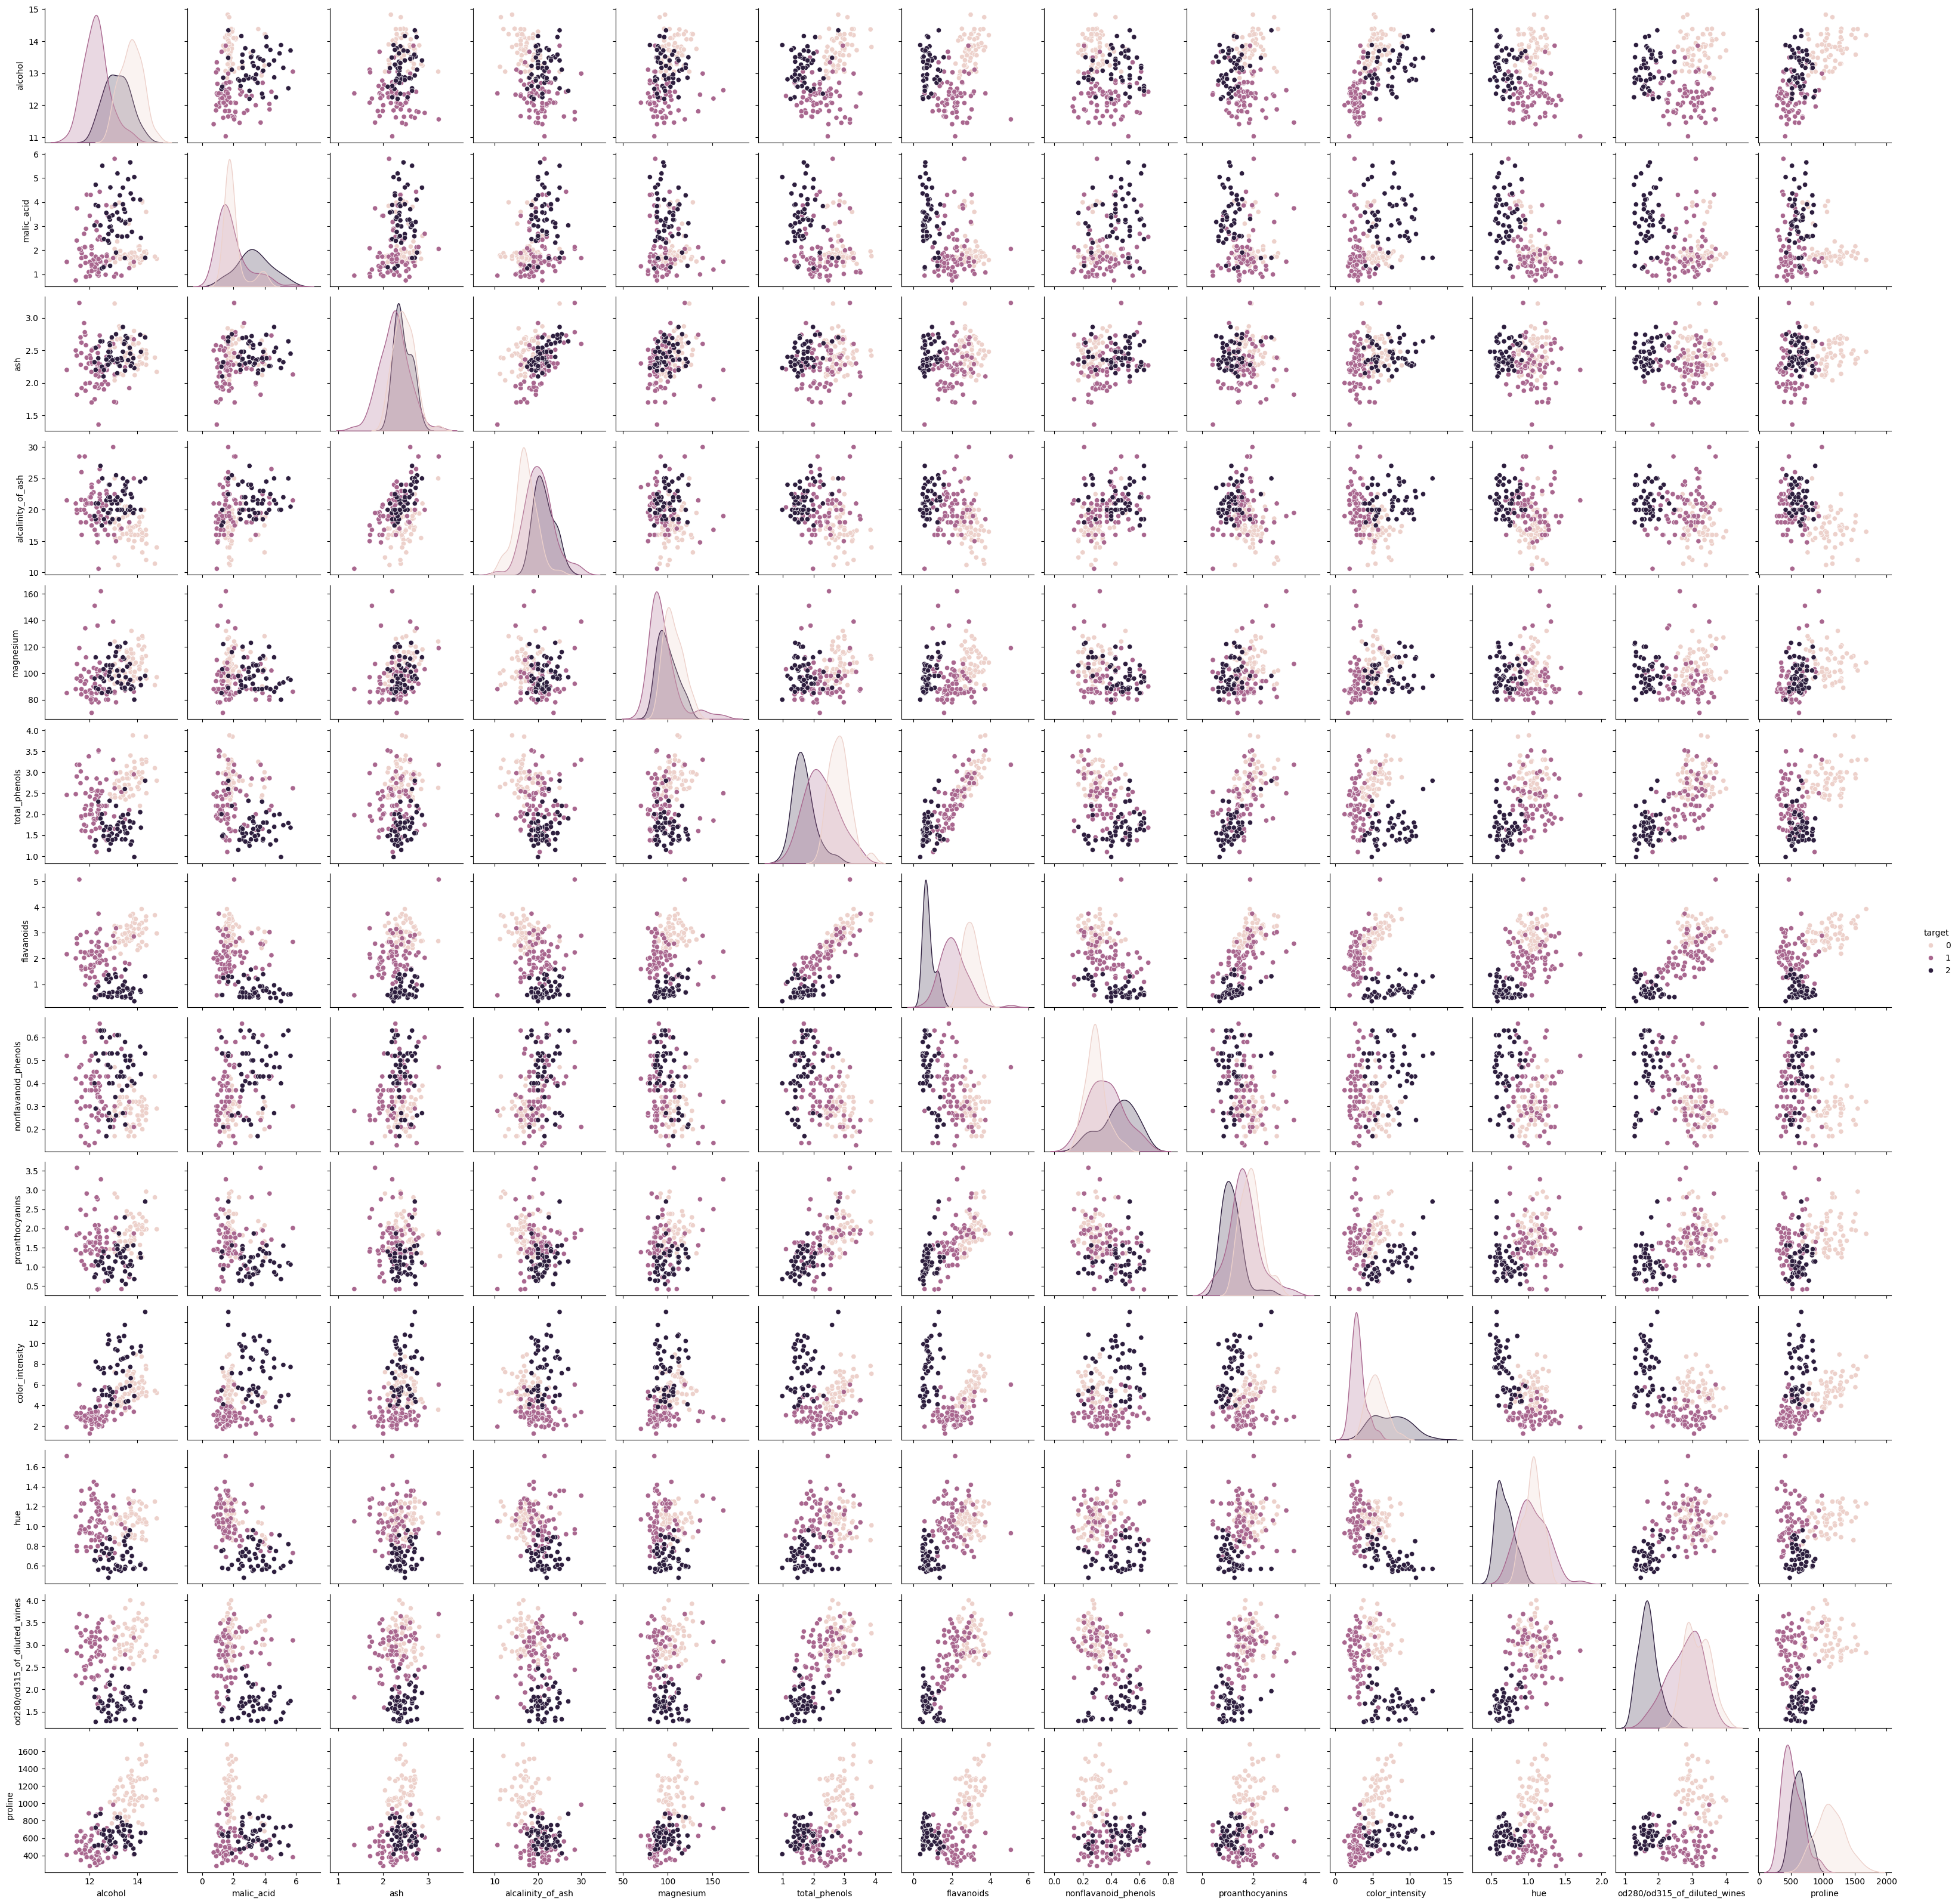

In [75]:
# code here

data = load_wine()
df = pd.DataFrame(data.data, columns=data.feature_names)
df["target"] = data.target

df.head()

features = [
    'alcohol',
    'malic_acid',
    'ash',
    'alcalinity_of_ash',
    'magnesium',
    'total_phenols',
    'flavanoids',
    'nonflavanoid_phenols',
    'proanthocyanins',
    'color_intensity',
    'hue',
    'od280/od315_of_diluted_wines',
    'proline'
]

sns.pairplot(
    df,
    vars=features,
    hue='target',
    diag_kind='kde'
)
# proline

#

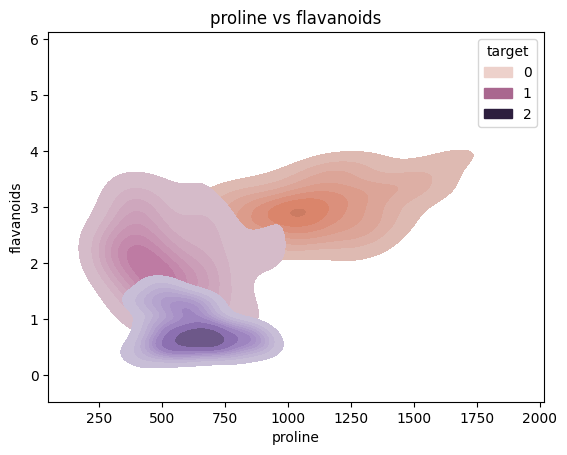

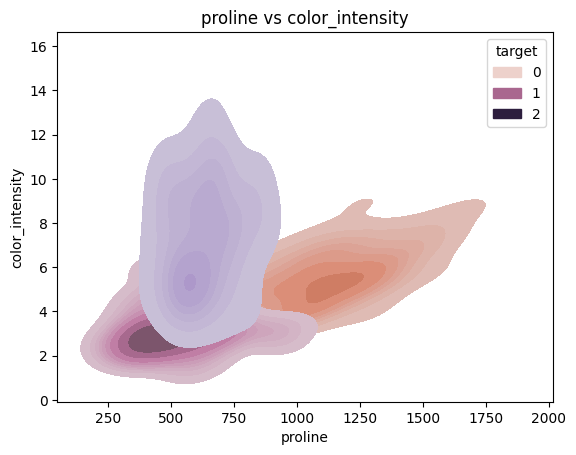

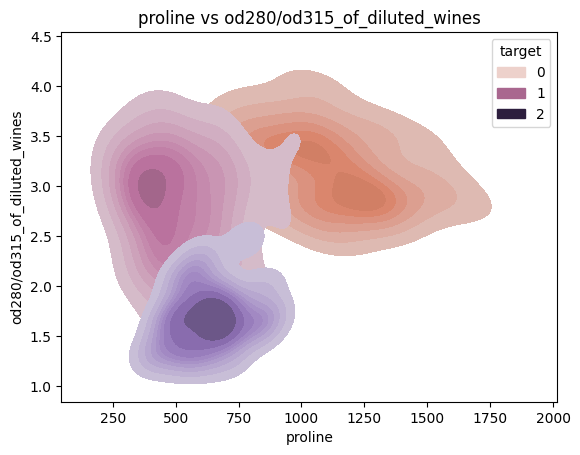

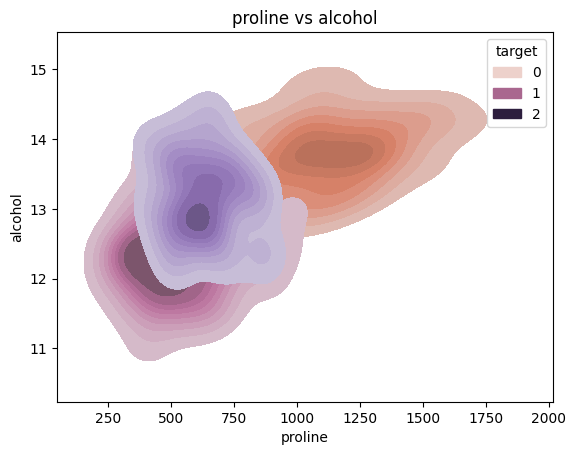

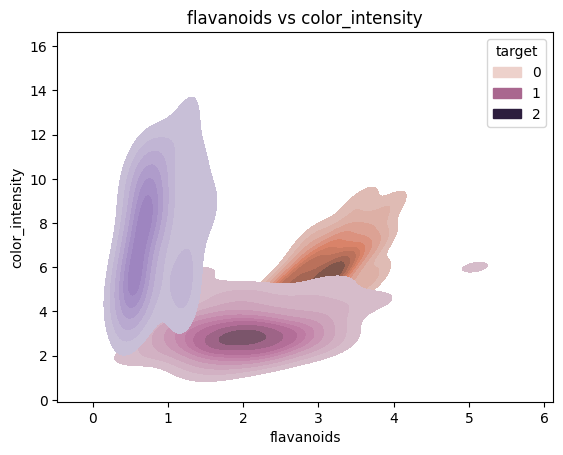

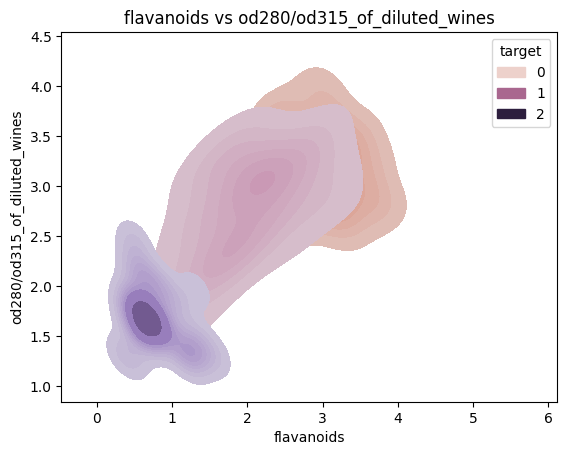

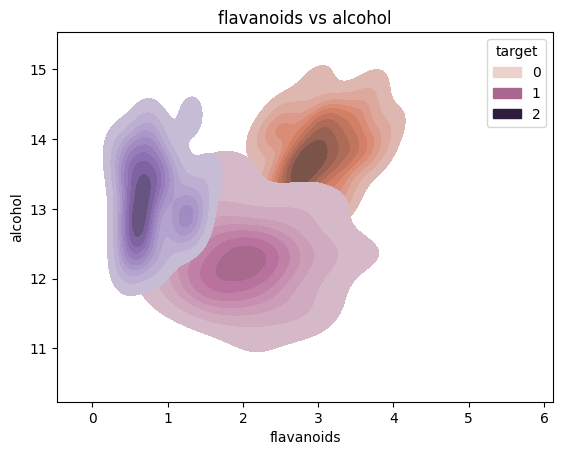

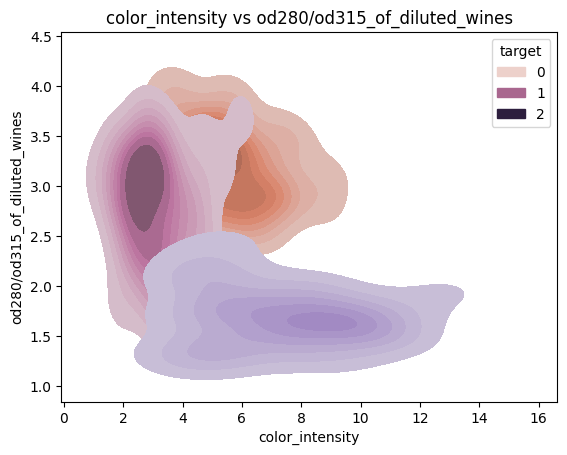

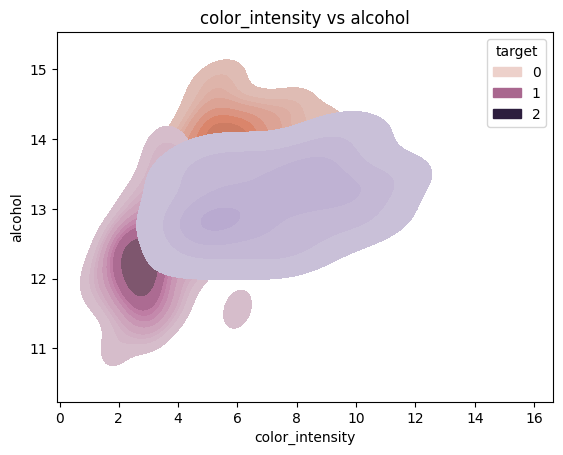

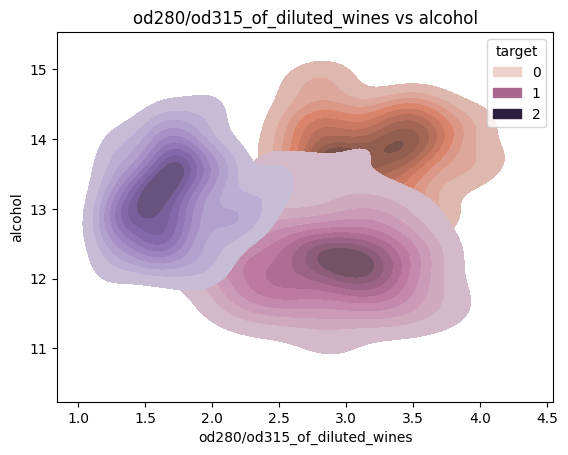

In [76]:
features = [
    'proline',
    'flavanoids',
    'color_intensity',
    'od280/od315_of_diluted_wines',
    'alcohol'
]

for i in range(len(features)):
    for j in range(i + 1, len(features)):
        sns.kdeplot(
            data=df,
            x=features[i],
            y=features[j],
            hue='target',
            fill=True
        )

        plt.title(f'{features[i]} vs {features[j]}')
        plt.show()

In [60]:
df.head()

,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline,target
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0,0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0,0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0,0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0,0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0,0
